``Understanding the Discrete Wavelet Transform (DWT)``
1. The Discrete Wavelet Transform (DWT) is a signal-processing technique that decomposes a signal into components at different frequency scales while retaining information about when those frequency components occur in time.
2. In a Fourier Transform, a signal is represented as a sum of sinusoidal frequencies. While this reveals which frequencies are present, the standard Fourier Transform does not preserve information about when those frequencies occur within the signal.
3. To retain both time and frequency information, techniques such as the Wavelet Transform can be used. The DWT achieves this by repeatedly decomposing the signal into low-frequency (approximation) and high-frequency (detail) components.
4. Let `*fs*` denote the sampling frequency of the signal.
5. At the first level of decomposition:
D1 (Detail Coefficients) contains the higher-frequency content of the signal, approximately corresponding to the frequency band:
`*fs/4 to fs/2*`

6. The highest frequency that can be represented in a sampled signal is the Nyquist frequency: `*2fs*`
7. A1 (Approximation Coefficients) contains the lower-frequency content of the signal, approximately corresponding to:
`*0 to fs/4*`
8. A1 is obtained by passing the original signal through a low-pass filter followed by downsampling. It represents a smoothed version of the original signal.

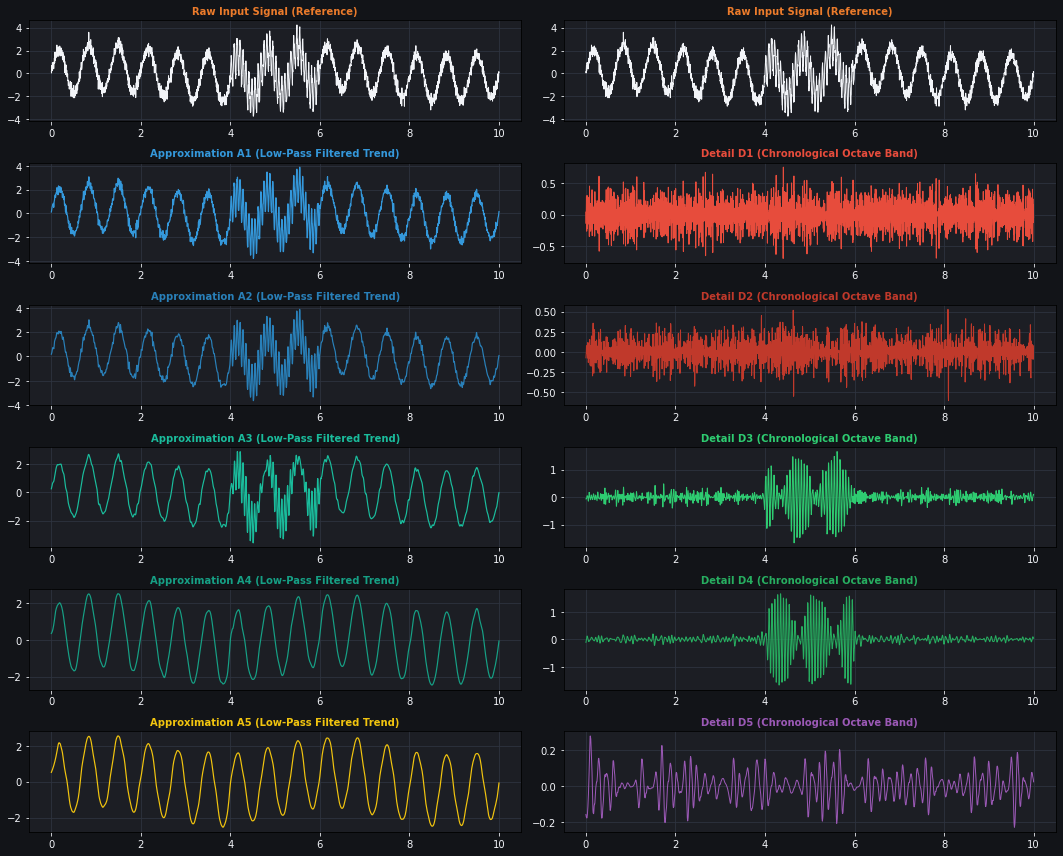

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# 1. Generate a synthetic 2500-sample timeline
np.random.seed(42)
t = np.linspace(0, 10, 2500)

# Create distinct frequency components running through the timeline
freq_slow_drift = 0.5 * np.sin(2 * np.pi * 0.2 * t)          # 0.2 Hz: Slow baseline sway
freq_main_pulse = 2.0 * np.sin(2 * np.pi * 1.5 * t)          # 1.5 Hz: Regular heart-like rhythm
freq_fast_burst = 1.5 * np.sin(2 * np.pi * 15 * t) * (t > 4) * (t < 6) # 15 Hz: Sudden temporary burst
freq_high_noise = 0.3 * np.random.normal(size=len(t))        # High-Freq: Unstructured line buzz

# Mix them all into a single chaotic signal
mixed_signal = freq_slow_drift + freq_main_pulse + freq_fast_burst + freq_high_noise

# 2. Perform a 5-Level Wavelet Decomposition using Daubechies 4 (db4)
wavelet_name = 'db4'
level = 5
coefficients = pywt.wavedec(mixed_signal, wavelet_name, level=level)

# Helper function to reconstruct a specific coefficient list back into a physical signal
def reconstruct_band(coeffs_list):
    recon = pywt.waverec(coeffs_list, wavelet_name)
    return recon[:len(mixed_signal)] # Ensure length matches exactly

# 3. Reconstruct Approximations (A1 through A5)
# Note: pywt.wavedec returns [A5, D5, D4, D3, D2, D1]
approx_signals = []
for i in range(1, level + 1):
    # To get Ai, we take the partial decomposition at that level
    coeffs_at_i = pywt.wavedec(mixed_signal, wavelet_name, level=i)
    # Zero out all detail layers at this level, keeping only the first element (Ai)
    ai_coeffs = [coeffs_at_i[0]] + [np.zeros_like(c) for c in coeffs_at_i[1:]]
    approx_signals.append(reconstruct_band(ai_coeffs))

# 4. Reconstruct Details (D1 through D5)
detail_signals = []
for i in range(1, level + 1):
    # To isolate Di, we use the full level-5 structure but zero out everything except Di's slot
    d_coeffs = [np.zeros_like(c) for c in coefficients]
    # In the level-5 list [A5, D5, D4, D3, D2, D1]:
    # D5 is index 1, D4 is index 2... D1 is index 5 -> map index mathematically:
    target_idx = level - i + 1
    d_coeffs[target_idx] = coefficients[target_idx]
    detail_signals.append(reconstruct_band(d_coeffs))

# 5. Plotting the Multi-Resolution Grid
fig, axes = plt.subplots(6, 2, figsize=(15, 12), facecolor='#121418')
ax_style = {'facecolor': '#1c1e24', 'grid_color': '#2e3440', 'labelcolor': '#f2f4f8'}

def style_axis(ax, title, color):
    ax.set_facecolor(ax_style['facecolor'])
    ax.grid(True, color=ax_style['grid_color'])
    ax.tick_params(colors=ax_style['labelcolor'])
    ax.set_title(title, fontsize=10, fontweight='bold', color=color)

# Top row: Raw signal shown on both columns as reference
style_axis(axes[0, 0], "Raw Input Signal (Reference)", '#eb7b2b')
axes[0, 0].plot(t, mixed_signal, color='#f2f4f8', linewidth=1)

style_axis(axes[0, 1], "Raw Input Signal (Reference)", '#eb7b2b')
axes[0, 1].plot(t, mixed_signal, color='#f2f4f8', linewidth=1)

# Plot Approximations (Left Column: A1 down to A5)
a_colors = ['#3498db', '#2980b9', '#1abc9c', '#16a085', '#f1c40f']
for idx in range(level):
    ax = axes[idx + 1, 0]
    style_axis(ax, f"Approximation A{idx+1} (Low-Pass Filtered Trend)", a_colors[idx])
    ax.plot(t, approx_signals[idx], color=a_colors[idx], linewidth=1.2)

# Plot Details (Right Column: D1 down to D5)
d_colors = ['#e74c3c', '#c0392b', '#2ecc71', '#27ae60', '#9b59b6']
for idx in range(level):
    ax = axes[idx + 1, 1]
    style_axis(ax, f"Detail D{idx+1} (Chronological Octave Band)", d_colors[idx])
    ax.plot(t, detail_signals[idx], color=d_colors[idx], linewidth=1)

plt.tight_layout()
plt.show()

c:\Users\Varun\AppData\Local\Programs\Python\Python310\lib\site-packages\pywt\_multilevel.py:43: UserWarning: Level value of 4 is too high: all coefficients will experience boundary effects.
  warnings.warn(


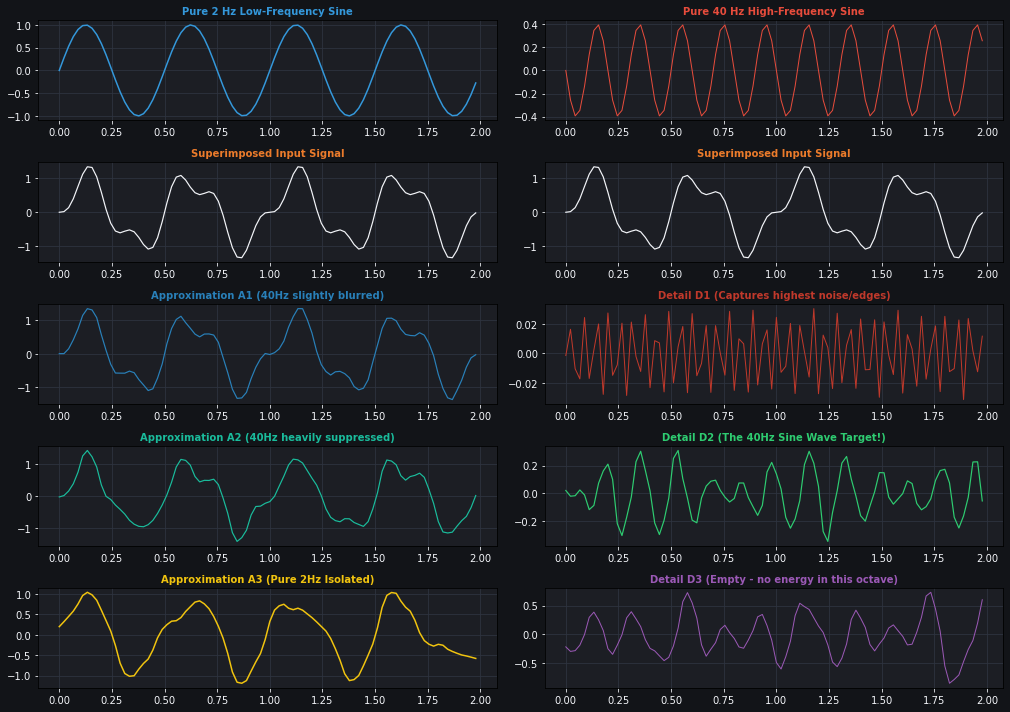

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# 1. Generate a clean 2-second timeline (initial Sampling rate: 500 Hz, later moved to lower values)
fs = 45  #sampling frequency  
# Sampling frequency can be max. twice the minimum freqeuncy in the signal or else the  min. frequency shall not be detected.
# we selected this to be  

t = np.linspace(0, 2, 2 * fs, endpoint=False)

# Create 2 pure, beautiful sine waves
freq_low = 1.0 * np.sin(2 * np.pi * 2 * t)     # 2 Hz: Slow sweeping wave
freq_high = 0.4 * np.sin(2 * np.pi * 40 * t)   # 40 Hz: Fast riding wave

# Superimpose them into a combined signal
superimposed_signal = freq_low + freq_high

# 2. Perform a 3-Level Wavelet Decomposition using Daubechies 4 (db4)
wavelet_name = 'db4'
level = 5
coefficients = pywt.wavedec(superimposed_signal, wavelet_name, level=level)

# Helper function to reconstruct individual sub-bands perfectly
def reconstruct_band(coeffs_list):
    recon = pywt.waverec(coeffs_list, wavelet_name)
    return recon[:len(superimposed_signal)]

# 3. Reconstruct Approximations (A1, A2, A3)
approx_signals = []
for i in range(1, level + 1):
    coeffs_at_i = pywt.wavedec(superimposed_signal, wavelet_name, level=i)
    ai_coeffs = [coeffs_at_i[0]] + [np.zeros_like(c) for c in coeffs_at_i[1:]]
    approx_signals.append(reconstruct_band(ai_coeffs))

# 4. Reconstruct Details (D1, D2, D3)
detail_signals = []
for i in range(1, level + 1):
    d_coeffs = [np.zeros_like(c) for c in coefficients]
    target_idx = level - i + 1
    d_coeffs[target_idx] = coefficients[target_idx]
    detail_signals.append(reconstruct_band(d_coeffs))

# 5. Plotting the entire experiment
fig, axes = plt.subplots(5, 2, figsize=(14, 10), facecolor='#121418')
ax_style = {'facecolor': '#1c1e24', 'grid_color': '#2e3440', 'labelcolor': '#f2f4f8'}

def style_axis(ax, title, color):
    ax.set_facecolor(ax_style['facecolor'])
    ax.grid(True, color=ax_style['grid_color'])
    ax.tick_params(colors=ax_style['labelcolor'])
    ax.title.set_color(ax_style['labelcolor'])
    ax.set_title(title, fontsize=10, fontweight='bold', color=color)

# --- LEFT COLUMN: Input & Approximations ---
style_axis(axes[0, 0], "Pure 2 Hz Low-Frequency Sine", '#3498db')
axes[0, 0].plot(t, freq_low, color='#3498db', linewidth=1.5)

style_axis(axes[1, 0], "Superimposed Input Signal", '#eb7b2b')
axes[1, 0].plot(t, superimposed_signal, color='#f2f4f8', linewidth=1.2)

style_axis(axes[2, 0], "Approximation A1 (40Hz slightly blurred)", '#2980b9')
axes[2, 0].plot(t, approx_signals[0], color='#2980b9', linewidth=1.2)

style_axis(axes[3, 0], "Approximation A2 (40Hz heavily suppressed)", '#1abc9c')
axes[3, 0].plot(t, approx_signals[1], color='#1abc9c', linewidth=1.2)

style_axis(axes[4, 0], "Approximation A3 (Pure 2Hz Isolated)", '#f1c40f')
axes[4, 0].plot(t, approx_signals[2], color='#f1c40f', linewidth=1.5)

# --- RIGHT COLUMN: Input & Details ---
style_axis(axes[0, 1], "Pure 40 Hz High-Frequency Sine", '#e74c3c')
axes[0, 1].plot(t, freq_high, color='#e74c3c', linewidth=1)

style_axis(axes[1, 1], "Superimposed Input Signal", '#eb7b2b')
axes[1, 1].plot(t, superimposed_signal, color='#f2f4f8', linewidth=1.2)

style_axis(axes[2, 1], "Detail D1 (Captures highest noise/edges)", '#c0392b')
axes[2, 1].plot(t, detail_signals[0], color='#c0392b', linewidth=1)

style_axis(axes[3, 1], "Detail D2 (The 40Hz Sine Wave Target!)", '#2ecc71')
axes[3, 1].plot(t, detail_signals[1], color='#2ecc71', linewidth=1.2)

style_axis(axes[4, 1], "Detail D3 (Empty - no energy in this octave)", '#9b59b6')
axes[4, 1].plot(t, detail_signals[2], color='#9b59b6', linewidth=1)

plt.tight_layout()
plt.show()